# TRUSTSR Lab 02 — Final Integrated Recovery and Audit Validation

**Project:** TRUSTSR — Trust-Aware Causal Semantic Recovery for Long-Horizon Agentic Systems  
**Lab series:** 02 — Recovery implementation  
**Status:** Integrated synthetic prototype  
**Version:** 1.0.0

## Purpose
This is the final lab in Lab 02. It combines the core ideas from the previous labs into one compact end-to-end test:
1. Validate a signed checkpoint.
2. Enforce monotonic checkpoint versions in SQLite with a transaction.
3. Record the decision in a SHA-256 hash-chained audit log.
4. Verify the audit chain and detect simple tampering.
5. Test rejection of stale, replayed, and invalid-signature checkpoints.
6. Demonstrate the important boundary: an audit hash chain is not independently tamper-proof if an attacker can replace the entire history and trusted head.

This is a compact integration lab, not a replacement for every detailed experiment in Labs 02.01–02.07. It should be treated as the final consolidation checkpoint for the series.

## Evidence boundary
**All checkpoint states, requests, and attack scenarios are synthetic.** Outputs are results from this notebook's local execution only. They do not establish production readiness, distributed consensus, crash durability, real-agent recovery effectiveness, or a formal security guarantee.

> **Revision note (v0.1.1 package review).** The whole-log-rewrite demonstration previously re-hashed an unchanged history, which reproduces the original head and made `assert not head_matches` fail. It now alters the first event before re-hashing.

## 1. Install and import

In [1]:
%pip -q install cryptography pandas matplotlib

In [2]:
import os, json, copy, sqlite3, tempfile, hashlib, uuid, sys, platform
from datetime import datetime, timezone
import pandas as pd
import matplotlib.pyplot as plt
from cryptography.hazmat.primitives.asymmetric.ed25519 import Ed25519PrivateKey
from cryptography.exceptions import InvalidSignature

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("SQLite:", sqlite3.sqlite_version)
print("Execution UTC:", datetime.now(timezone.utc).isoformat())
print("Evidence classification: synthetic integrated simulation")

Python: 3.12.3
Platform: Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
SQLite: 3.45.1
Execution UTC: 2026-10-11T10:26:33.648693+00:00
Evidence classification: synthetic integrated simulation


## 2. Signed checkpoint fixtures

In [3]:
private_key = Ed25519PrivateKey.generate()
public_key = private_key.public_key()

def canonical_bytes(obj):
    return json.dumps(obj, sort_keys=True, separators=(",", ":"), ensure_ascii=False).encode("utf-8")

def sign_checkpoint(version, state_value):
    checkpoint = {"schema_version": 1, "checkpoint_version": version, "state": {"memory": state_value}}
    signature = private_key.sign(canonical_bytes(checkpoint))
    return {"checkpoint": checkpoint, "signature": signature}

def verify_signature(signed):
    try:
        public_key.verify(signed["signature"], canonical_bytes(signed["checkpoint"]))
        return True
    except (InvalidSignature, KeyError, TypeError):
        return False

signed_checkpoints = {
    version: sign_checkpoint(version, f"synthetic-state-v{version}")
    for version in range(1, 6)
}
assert all(verify_signature(item) for item in signed_checkpoints.values())
print("Prepared valid signed checkpoint versions:", list(signed_checkpoints))

Prepared valid signed checkpoint versions: [1, 2, 3, 4, 5]


## 3. SQLite version guard

In [4]:
db_fd, db_path = tempfile.mkstemp(prefix="trustsr_lab02_final_", suffix=".sqlite")
os.close(db_fd)

def connect_db():
    db = sqlite3.connect(db_path, timeout=10, isolation_level=None, check_same_thread=False)
    db.execute("PRAGMA journal_mode=WAL")
    db.execute("PRAGMA synchronous=FULL")
    db.execute("""
        CREATE TABLE IF NOT EXISTS checkpoint_guard (
            singleton_id INTEGER PRIMARY KEY CHECK (singleton_id = 1),
            high_water_mark INTEGER NOT NULL CHECK (high_water_mark >= 0)
        )
    """)
    db.execute("INSERT OR IGNORE INTO checkpoint_guard(singleton_id, high_water_mark) VALUES (1, 0)")
    return db

db = connect_db()

def current_mark(connection=db):
    return int(connection.execute(
        "SELECT high_water_mark FROM checkpoint_guard WHERE singleton_id=1"
    ).fetchone()[0])

print("Initial checkpoint high-water mark:", current_mark())

Initial checkpoint high-water mark: 0


## 4. Hash-chained audit records

In [5]:
GENESIS_HASH = "0" * 64
audit_log = []

def calculate_event_hash(event_without_hash):
    return hashlib.sha256(canonical_bytes(event_without_hash)).hexdigest()

def append_audit_event(*, txid, version, outcome, reason, mark_before, mark_after):
    event = {
        "sequence": len(audit_log) + 1,
        "transaction_id": txid,
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "checkpoint_version": version,
        "outcome": outcome,
        "reason": reason,
        "mark_before": mark_before,
        "mark_after": mark_after,
        "previous_hash": audit_log[-1]["event_hash"] if audit_log else GENESIS_HASH,
    }
    event["event_hash"] = calculate_event_hash(event)
    audit_log.append(event)
    return event

def verify_audit_chain(log):
    issues = []
    previous_hash = GENESIS_HASH
    for expected_seq, stored in enumerate(log, start=1):
        event = copy.deepcopy(stored)
        stored_hash = event.pop("event_hash", None)
        if event.get("sequence") != expected_seq:
            issues.append({"sequence": expected_seq, "issue": "sequence_gap_or_reordering"})
        if event.get("previous_hash") != previous_hash:
            issues.append({"sequence": expected_seq, "issue": "previous_hash_mismatch"})
        if stored_hash != calculate_event_hash(event):
            issues.append({"sequence": expected_seq, "issue": "event_hash_mismatch"})
        previous_hash = stored_hash if isinstance(stored_hash, str) else ""
    return {"valid": not issues, "issues": issues, "events_checked": len(log)}

print("Audit-chain writer and verifier defined.")

Audit-chain writer and verifier defined.


## 5. Integrated checkpoint decision

In [6]:
def submit_checkpoint(signed, *, inject_precommit_failure=False):
    txid = str(uuid.uuid4())
    if not verify_signature(signed):
        before = current_mark()
        append_audit_event(txid=txid, version=None, outcome="rejected",
                           reason="invalid_signature", mark_before=before, mark_after=before)
        return {"transaction_id": txid, "accepted": False, "reason": "invalid_signature",
                "mark_before": before, "mark_after": current_mark()}

    checkpoint = signed["checkpoint"]
    version = checkpoint.get("checkpoint_version")
    if not isinstance(version, int) or isinstance(version, bool) or version < 1:
        before = current_mark()
        append_audit_event(txid=txid, version=version, outcome="rejected",
                           reason="invalid_version", mark_before=before, mark_after=before)
        return {"transaction_id": txid, "accepted": False, "reason": "invalid_version",
                "mark_before": before, "mark_after": current_mark()}

    try:
        db.execute("BEGIN IMMEDIATE")
        before = current_mark()
        if version <= before:
            db.execute("ROLLBACK")
            after = current_mark()
            append_audit_event(txid=txid, version=version, outcome="rejected",
                               reason="stale_or_replay", mark_before=before, mark_after=after)
            return {"transaction_id": txid, "accepted": False, "reason": "stale_or_replay",
                    "mark_before": before, "mark_after": after}

        cursor = db.execute(
            "UPDATE checkpoint_guard SET high_water_mark=? "
            "WHERE singleton_id=1 AND high_water_mark=?",
            (version, before)
        )
        if cursor.rowcount != 1:
            db.execute("ROLLBACK")
            after = current_mark()
            append_audit_event(txid=txid, version=version, outcome="rejected",
                               reason="compare_and_update_conflict", mark_before=before, mark_after=after)
            return {"transaction_id": txid, "accepted": False, "reason": "compare_and_update_conflict",
                    "mark_before": before, "mark_after": after}

        if inject_precommit_failure:
            db.execute("ROLLBACK")
            after = current_mark()
            append_audit_event(txid=txid, version=version, outcome="rejected",
                               reason="simulated_precommit_rollback", mark_before=before, mark_after=after)
            return {"transaction_id": txid, "accepted": False, "reason": "simulated_precommit_rollback",
                    "mark_before": before, "mark_after": after}

        db.execute("COMMIT")
        after = current_mark()
        append_audit_event(txid=txid, version=version, outcome="accepted",
                           reason="committed", mark_before=before, mark_after=after)
        return {"transaction_id": txid, "accepted": True, "reason": "committed",
                "mark_before": before, "mark_after": after}
    except Exception as exc:
        try:
            db.execute("ROLLBACK")
        except sqlite3.Error:
            pass
        after = current_mark()
        append_audit_event(txid=txid, version=version, outcome="error",
                           reason=f"database_error:{type(exc).__name__}", mark_before=before if 'before' in locals() else after,
                           mark_after=after)
        return {"transaction_id": txid, "accepted": False, "reason": f"database_error:{type(exc).__name__}",
                "mark_before": before if 'before' in locals() else after, "mark_after": after}

print("Integrated submit function defined.")

Integrated submit function defined.


## 6. Run synthetic acceptance, replay, signature, and rollback tests

In [7]:
results = []

def run_case(name, signed, expected_accepted, expected_mark, **kwargs):
    result = submit_checkpoint(signed, **kwargs)
    row = {
        "scenario": name,
        "accepted": result["accepted"],
        "reason": result["reason"],
        "mark_before": result["mark_before"],
        "mark_after": result["mark_after"],
        "expected_accepted": expected_accepted,
        "expected_mark_after": expected_mark,
        "assertion_passed": result["accepted"] == expected_accepted and result["mark_after"] == expected_mark,
        "transaction_id": result["transaction_id"],
    }
    results.append(row)
    assert row["assertion_passed"], row
    return result

r1 = run_case("accept_v2", signed_checkpoints[2], True, 2)
r2 = run_case("reject_stale_v1", signed_checkpoints[1], False, 2)
r3 = run_case("reject_equal_replay_v2", signed_checkpoints[2], False, 2)
r4 = run_case("rollback_v4_before_commit", signed_checkpoints[4], False, 2, inject_precommit_failure=True)

tampered = copy.deepcopy(signed_checkpoints[5])
tampered["checkpoint"]["state"]["memory"] = "altered-after-signing"
r5 = run_case("reject_tampered_signature", tampered, False, 2)

r6 = run_case("accept_v3_after_rollback", signed_checkpoints[3], True, 3)

results_df = pd.DataFrame(results)
display(results_df)
print("High-water mark after scenarios:", current_mark())

                    scenario  accepted                        reason  mark_before  mark_after  expected_accepted  expected_mark_after  assertion_passed                        transaction_id
0                  accept_v2      True                     committed            0           2               True                    2              True  8760105a-9a7e-4c3d-b8b7-d9b1e32bd7a7
1            reject_stale_v1     False               stale_or_replay            2           2              False                    2              True  71400d37-9cb3-43b0-87b2-620af30ec83c
2     reject_equal_replay_v2     False               stale_or_replay            2           2              False                    2              True  f5943947-920f-48e8-ba2a-276ac26250dd
3  rollback_v4_before_commit     False  simulated_precommit_rollback            2           2              False                    2              True  4ec1899b-7766-4c10-a8b8-8a1635eecfe5
4  reject_tampered_signature     False            

High-water mark after scenarios: 3


## 7. Verify audit consistency and test tampering

In [8]:
chain_check = verify_audit_chain(audit_log)
audit_df = pd.DataFrame(audit_log)
display(audit_df)
print("Audit chain verification:", chain_check)
assert chain_check["valid"]
assert len(audit_log) == len(results_df)
assert results_df["assertion_passed"].all()

mutated_log = copy.deepcopy(audit_log)
mutated_log[0]["reason"] = "undetectably-looking-rewrite"
tamper_check = verify_audit_chain(mutated_log)
print("Tampered chain verification:", tamper_check)
assert not tamper_check["valid"]

# Demonstrate why an independent trusted head matters.
rewritten_log = []
for old in audit_log:
    event = {k: v for k, v in old.items() if k not in ("previous_hash", "event_hash")}
    if not rewritten_log:  # an attacker rewriting history must actually change something
        event["reason"] = "attacker-rewritten-history"
    event["previous_hash"] = rewritten_log[-1]["event_hash"] if rewritten_log else GENESIS_HASH
    event["event_hash"] = calculate_event_hash(event)
    rewritten_log.append(event)
rewritten_check = verify_audit_chain(rewritten_log)
head_matches = rewritten_log[-1]["event_hash"] == audit_log[-1]["event_hash"]
assert rewritten_check["valid"]
assert not head_matches
print("Whole-log rewrite remains internally valid:", rewritten_check["valid"])
print("Rewritten head matches original head:", head_matches)

   sequence                        transaction_id                     timestamp_utc  checkpoint_version   outcome                        reason  mark_before  mark_after  \
0         1  8760105a-9a7e-4c3d-b8b7-d9b1e32bd7a7  2026-10-11T10:26:33.656761+00:00                 2.0  accepted                     committed            0           2   
1         2  71400d37-9cb3-43b0-87b2-620af30ec83c  2026-10-11T10:26:33.657062+00:00                 1.0  rejected               stale_or_replay            2           2   
2         3  f5943947-920f-48e8-ba2a-276ac26250dd  2026-10-11T10:26:33.657352+00:00                 2.0  rejected               stale_or_replay            2           2   
3         4  4ec1899b-7766-4c10-a8b8-8a1635eecfe5  2026-10-11T10:26:33.657581+00:00                 4.0  rejected  simulated_precommit_rollback            2           2   
4         5  f717cff4-ffa2-4c79-b434-bcc17f1ac919  2026-10-11T10:26:33.657798+00:00                 NaN  rejected             invalid_signat

Audit chain verification: {'valid': True, 'issues': [], 'events_checked': 6}
Tampered chain verification: {'valid': False, 'issues': [{'sequence': 1, 'issue': 'event_hash_mismatch'}], 'events_checked': 6}
Whole-log rewrite remains internally valid: True
Rewritten head matches original head: False


## 8. Plot integrated scenario outcomes

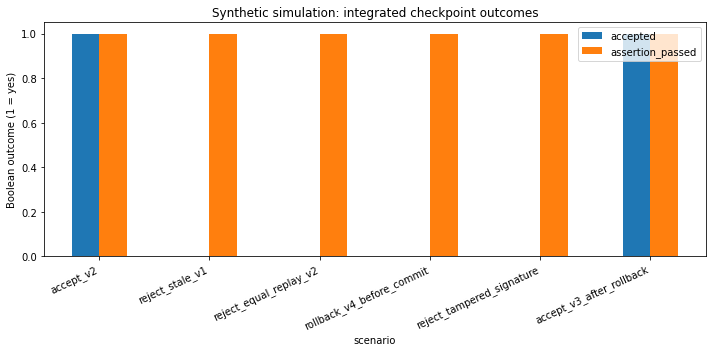

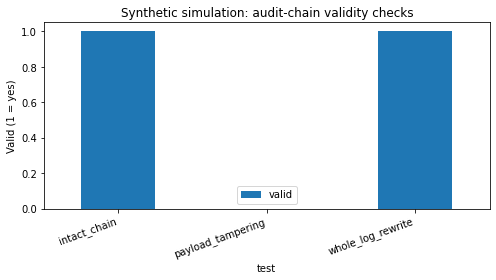

In [9]:
plot_df = results_df.set_index("scenario")[["accepted", "assertion_passed"]].astype(int)
ax = plot_df.plot(kind="bar", figsize=(10, 5))
ax.set_ylabel("Boolean outcome (1 = yes)")
ax.set_title("Synthetic simulation: integrated checkpoint outcomes")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

tamper_plot = pd.DataFrame([
    {"test": "intact_chain", "valid": verify_audit_chain(audit_log)["valid"]},
    {"test": "payload_tampering", "valid": verify_audit_chain(mutated_log)["valid"]},
    {"test": "whole_log_rewrite", "valid": rewritten_check["valid"]},
]).set_index("test")
tamper_plot.astype(int).plot(kind="bar", figsize=(7, 4), title="Synthetic simulation: audit-chain validity checks")
plt.ylabel("Valid (1 = yes)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 9. Export CSV evidence

In [10]:
results_df.to_csv("trustsr_lab02_final_checkpoint_scenarios.csv", index=False)
audit_df.to_csv("trustsr_lab02_final_audit_log.csv", index=False)
pd.DataFrame([
    {"test":"intact_chain","valid":verify_audit_chain(audit_log)["valid"]},
    {"test":"payload_tampering","valid":verify_audit_chain(mutated_log)["valid"]},
    {"test":"whole_log_rewrite","valid":rewritten_check["valid"]},
    {"test":"rewritten_head_matches_original","valid":head_matches},
]).to_csv("trustsr_lab02_final_audit_validation.csv", index=False)

print("Generated CSVs:")
print("- trustsr_lab02_final_checkpoint_scenarios.csv")
print("- trustsr_lab02_final_audit_log.csv")
print("- trustsr_lab02_final_audit_validation.csv")

Generated CSVs:
- trustsr_lab02_final_checkpoint_scenarios.csv
- trustsr_lab02_final_audit_log.csv
- trustsr_lab02_final_audit_validation.csv


## 10. Final assertions and summary

In [11]:
assert current_mark() == 3
assert results_df["assertion_passed"].all()
assert verify_audit_chain(audit_log)["valid"]
assert not verify_audit_chain(mutated_log)["valid"]
assert verify_audit_chain(rewritten_log)["valid"]
assert not head_matches
assert len({event["transaction_id"] for event in audit_log}) == len(audit_log)

print("PASS: valid newer checkpoints advance the mark.")
print("PASS: stale and replayed checkpoints are rejected.")
print("PASS: modified signed checkpoint is rejected.")
print("PASS: simulated pre-commit failure rolls back.")
print("PASS: every decision in this synthetic run has a matching audit event.")
print("PASS: local audit tampering is detected.")
print("PASS: whole-log rewrite illustrates the trusted-head limitation.")
print("All TRUSTSR Lab 02 FINAL assertions passed.")

PASS: valid newer checkpoints advance the mark.
PASS: stale and replayed checkpoints are rejected.
PASS: modified signed checkpoint is rejected.
PASS: simulated pre-commit failure rolls back.
PASS: every decision in this synthetic run has a matching audit event.
PASS: local audit tampering is detected.
PASS: whole-log rewrite illustrates the trusted-head limitation.
All TRUSTSR Lab 02 FINAL assertions passed.


## 11. Interpretation and limitations

### What this final lab demonstrates
Within this synthetic notebook run, signed checkpoint fixtures are checked, SQLite enforces monotonic version updates, stale/replayed/tampered submissions are rejected, a simulated pre-commit failure is rolled back, and decisions are recorded in a verifiable hash-chained audit list.

### Integration caveat
The SQLite transaction and audit append are **not one atomic transaction**: the checkpoint commit occurs before the in-memory audit event is appended. A crash between those operations could leave a committed checkpoint without its audit event. This is a known limitation, not a solved property. A production design would need an outbox/transactional audit table in the same database transaction, or another explicitly specified consistency protocol.

### Security and evidence boundary
- This is a local synthetic simulation, not a deployed agent or production system.
- SQLite local transactions do not prove distributed consensus or power-loss guarantees.
- The generated signing key is ephemeral and not securely managed.
- Hash chaining alone cannot stop an attacker who can replace the entire history and trusted head; external anchoring or protected storage is needed.
- Passing assertions establishes only that these specific tests passed under this execution environment.
- No claim is made here about real-world recovery effectiveness, general attack detection rates, or formal security guarantees.

### Lab 02 completion
Lab 02 is complete as a **prototype learning/evaluation sequence**, not as a validated production implementation. Preserve the executed notebook, CSV outputs, environment details, and failure analysis as synthetic evidence. Before making research claims, fix the audit/checkpoint atomicity gap and evaluate a documented implementation with reproducible tests.